# Diagnosing misspecification in the population

Three known structural systems separate omitted-common-cause bias, collider bias, and conditioning on a confounded mediator:

$$
\begin{aligned}
\text{Fork:}\quad &Z=\varepsilon_Z,\quad X=Z+\varepsilon_X,\quad Y=Z+\varepsilon_Y,\\
\text{Collider:}\quad &X=\varepsilon_X,\quad Y=\varepsilon_Y,\quad Z=X+Y+\varepsilon_Z,\\
\text{Confounded mediator:}\quad &X=\varepsilon_X,\quad W=\varepsilon_W,\quad Z=X+W+\varepsilon_Z,\quad Y=Z+W+\varepsilon_Y.
\end{aligned}
$$

Here, $X$ is the exposure, $Y$ is the outcome, $Z$ is respectively a common cause, a collider, or a mediator, $W$ is an unobserved common cause of the mediator and outcome, and every $\varepsilon$ is an independent standard-normal disturbance.

## Notebook setup

### Number formatting for tables

In [ ]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)




### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from dataclasses import FrozenInstanceError
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd



## Display float

In [ ]:
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

from RiskLabAI.causal_factor_analysis import ColliderCoefficients, ColliderDiagnostics, PopulationRegressionDiagnostics, RegressionDiagnostics, SpecificationExperimentResult, SpecificationPopulationResult, StrategyPerformance, collider_factor_return, collider_forecast_return, collider_model_diagnostics, collider_overcontrolled_coefficients, collider_population_diagnostics, collider_specification_experiment, confounded_mediator_population_diagnostics, confounded_mediator_specification_experiment, confounder_factor_return, confounder_forecast_return, confounder_undercontrolled_coefficient, fork_population_diagnostics, fork_specification_experiment, generalized_collider_overcontrolled_coefficients, generalized_confounder_undercontrolled_coefficient

FIGURES = ROOT / "outputs" / "figures" / "04_factor_mirage"
TABLES = ROOT / "outputs" / "tables" / "04_factor_mirage"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float);



## Table display and number formatting

In [ ]:
def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display_notebook_figure(figure)
    plt.close(figure)



## Contract result

In [ ]:
def contract_result(name, action, expected):
    try:
        action()
        return {"Check": name, "Expected result": expected, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        return {"Check": name, "Expected result": expected, "Observed result": type(error).__name__, "Passed": type(error).__name__ == expected}

def draw_graph(axis, nodes, edges, positions, title, colors=None):
    graph = nx.DiGraph()
    graph.add_nodes_from(nodes)
    graph.add_edges_from(edges)
    node_colors = colors if colors is not None else [palette["cyan"]] * len(nodes)
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=1650, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, font_color=palette["background"], font_weight="bold")
    nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20)
    axis.set_title(title)
    axis.set_axis_off()



## Ols diagnostics

In [ ]:
def ols_diagnostics(outcome, predictors):
    design = np.column_stack([np.ones(len(outcome))] + [np.asarray(values, dtype=float) for values in predictors.values()])
    coefficients = np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0]
    residuals = np.asarray(outcome, dtype=float) - design @ coefficients
    residual_degrees = len(outcome) - design.shape[1]
    residual_variance = float(residuals @ residuals / residual_degrees)
    covariance = np.linalg.inv(design.T @ design) * residual_variance
    standard_errors = np.sqrt(np.diag(covariance))
    centered = np.asarray(outcome, dtype=float) - np.mean(outcome)
    r_squared = 1.0 - float(residuals @ residuals) / float(centered @ centered)
    adjusted = 1.0 - (1.0 - r_squared) * (len(outcome) - 1) / residual_degrees
    names = ["Intercept"] + list(predictors)
    return pd.DataFrame({"Coefficient": names, "Estimate": coefficients, "Standard error": standard_errors, "Test signal": coefficients / standard_errors}), r_squared, adjusted, residual_variance

def coefficient_value(diagnostics, name):
    return diagnostics.coefficients[diagnostics.coefficient_names.index(name)]

population_functions = {
    "Fork": fork_population_diagnostics,
    "Collider": collider_population_diagnostics,
    "Confounded mediator": confounded_mediator_population_diagnostics,
}
experiment_functions = {
    "Fork": fork_specification_experiment,
    "Collider": collider_specification_experiment,
    "Confounded mediator": confounded_mediator_specification_experiment,
}



## Visible generated data

In [ ]:
def visible_generated_data(structure, sample_size, seed):
    random_state = np.random.RandomState(seed)
    if structure == "Fork":
        common_cause = random_state.standard_normal(sample_size)
        exposure = common_cause + random_state.standard_normal(sample_size)
        outcome = common_cause + random_state.standard_normal(sample_size)
        return {"X": exposure, "Y": outcome, "Z": common_cause}
    if structure == "Collider":
        exposure = random_state.standard_normal(sample_size)
        outcome = random_state.standard_normal(sample_size)
        collider = exposure + outcome + random_state.standard_normal(sample_size)
        return {"X": exposure, "Y": outcome, "Z": collider}
    exposure = random_state.standard_normal(sample_size)
    common_cause = random_state.standard_normal(sample_size)
    mediator = exposure + common_cause + random_state.standard_normal(sample_size)
    outcome = mediator + common_cause + random_state.standard_normal(sample_size)
    return {"X": exposure, "Y": outcome, "Z": mediator, "W": common_cause}

def manual_experiment(structure, sample_size=5000, seed=0):
    values = visible_generated_data(structure, sample_size, seed)
    unconditioned, unconditioned_r2, unconditioned_adjusted, unconditioned_residual = ols_diagnostics(values["Y"], {"X": values["X"]})
    conditioned, conditioned_r2, conditioned_adjusted, conditioned_residual = ols_diagnostics(values["Y"], {"X": values["X"], "Z": values["Z"]})
    return unconditioned, unconditioned_r2, unconditioned_adjusted, unconditioned_residual, conditioned, conditioned_r2, conditioned_adjusted, conditioned_residual



## Exact population targets for the three structural systems

,Structure,Variable role,Specification,Exposure coefficient,Conditioning-variable coefficient,Explained variance
0,Fork,Confounder,Conditioning variable omitted,0.5,NaN,0.25
1,Fork,Confounder,Conditioning variable included,0,1,0.5
2,Collider,Collider,Conditioning variable omitted,0,NaN,0
3,Collider,Collider,Conditioning variable included,-0.5,0.5,0.5
4,Confounded mediator,Confounded Mediator,Conditioning variable omitted,1,NaN,0.142857
5,Confounded mediator,Confounded Mediator,Conditioning variable included,-0.5,1.5,0.785714


,Structure,Specification,Exposure coefficient,Exposure standard error,Exposure test signal,Conditioning-variable coefficient,Explained variance,Adjusted explained variance,Residual variance,Observations,Seed
0,Fork,Conditioning variable omitted,0.496351,0.012258,40.492929,NaN,0.247026,0.246875,1.467531,5000,0
1,Fork,Conditioning variable included,0.00072,0.01418,0.050793,0.995713,0.494804,0.494602,0.984813,5000,0
2,Collider,Conditioning variable omitted,0.001504,0.014208,0.105821,NaN,0.000002,-0.000198,0.98001,5000,0
3,Collider,Conditioning variable included,-0.496296,0.012283,-40.404614,0.498828,0.499189,0.498988,0.490899,5000,0
4,Confounded mediator,Conditioning variable omitted,1.005503,0.034677,28.996195,NaN,0.143999,0.143828,5.837458,5000,0
5,Confounded mediator,Conditioning variable included,-0.481367,0.021279,-22.621343,1.489942,0.784001,0.783915,1.473289,5000,0


,Structure,Manual omitted coefficient,Library omitted coefficient,Manual included coefficient,Library included coefficient,Maximum difference
0,Fork,0.496351,0.496351,0.00072,0.00072,0
1,Collider,0.001504,0.001504,-0.496296,-0.496296,0
2,Confounded mediator,1.005503,1.005503,-0.481367,-0.481367,0


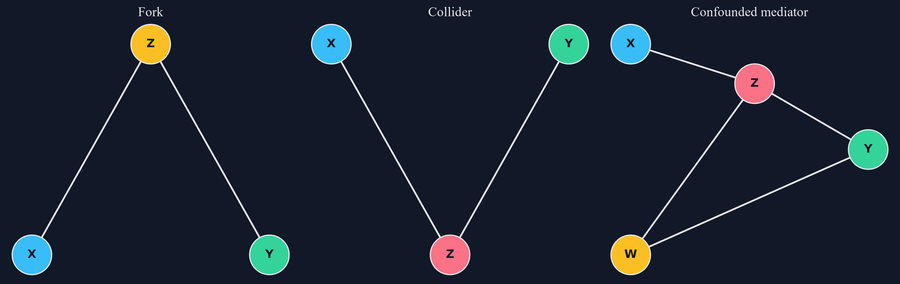

In [1]:
population_rows = []
sample_rows = []
parity_rows = []
for structure in population_functions:
    population = population_functions[structure]()
    experiment = experiment_functions[structure](sample_size=5000, seed=0)
    manual = manual_experiment(structure)
    for specification, population_diagnostics, sample_diagnostics in [("Conditioning variable omitted", population.unconditioned, experiment.unconditioned), ("Conditioning variable included", population.conditioned, experiment.conditioned)]:
        population_rows.append({"Structure": structure, "Variable role": population.conditioning_variable_role.replace("_", " ").title(), "Specification": specification, "Exposure coefficient": coefficient_value(population_diagnostics, "X"), "Conditioning-variable coefficient": coefficient_value(population_diagnostics, "Z") if "Z" in population_diagnostics.coefficient_names else np.nan, "Explained variance": population_diagnostics.r_squared})
        sample_rows.append({"Structure": structure, "Specification": specification, "Exposure coefficient": coefficient_value(sample_diagnostics, "X"), "Exposure standard error": sample_diagnostics.standard_errors[sample_diagnostics.coefficient_names.index("X")], "Exposure test signal": sample_diagnostics.t_statistics[sample_diagnostics.coefficient_names.index("X")], "Conditioning-variable coefficient": coefficient_value(sample_diagnostics, "Z") if "Z" in sample_diagnostics.coefficient_names else np.nan, "Explained variance": sample_diagnostics.r_squared, "Adjusted explained variance": sample_diagnostics.adjusted_r_squared, "Residual variance": sample_diagnostics.residual_variance, "Observations": sample_diagnostics.n_observations, "Seed": 0})
    manual_unconditioned = manual[0]
    manual_conditioned = manual[4]
    parity_rows.append({"Structure": structure, "Manual omitted coefficient": manual_unconditioned.loc[1, "Estimate"], "Library omitted coefficient": coefficient_value(experiment.unconditioned, "X"), "Manual included coefficient": manual_conditioned.loc[1, "Estimate"], "Library included coefficient": coefficient_value(experiment.conditioned, "X"), "Maximum difference": max(abs(manual_unconditioned.loc[1, "Estimate"] - coefficient_value(experiment.unconditioned, "X")), abs(manual_conditioned.loc[1, "Estimate"] - coefficient_value(experiment.conditioned, "X")))})
population_table = pd.DataFrame(population_rows)
sample_table = pd.DataFrame(sample_rows)
parity_table = pd.DataFrame(parity_rows)
save_table(population_table, "specification_population_targets", "Exact population targets for the three structural systems.", "tab:chapter26-specification-population-targets")
save_table(sample_table, "specification_seed_zero_samples", "Seed-zero sample diagnostics with 5,000 observations.", "tab:chapter26-specification-seed-zero")
save_table(parity_table, "specification_visible_generation_parity", "Visible generation agrees with the released fixed-seed experiments.", "tab:chapter26-specification-generation-parity", float_format="%.12g")
display(population_table)
display(sample_table)
display(parity_table)

figure, axes = plt.subplots(1, 3, figsize=(13.0, 4.2))
draw_graph(axes[0], ("Z", "X", "Y"), (("Z", "X"), ("Z", "Y")), {"Z": (0.9, 1.0), "X": (0.0, 0.0), "Y": (1.8, 0.0)}, "Fork", [palette["amber"], palette["cyan"], palette["green"]])
draw_graph(axes[1], ("X", "Y", "Z"), (("X", "Z"), ("Y", "Z")), {"X": (0.0, 0.0), "Y": (1.8, 0.0), "Z": (0.9, -1.0)}, "Collider", [palette["cyan"], palette["green"], palette["rose"]])
draw_graph(axes[2], ("X", "W", "Z", "Y"), (("X", "Z"), ("W", "Z"), ("W", "Y"), ("Z", "Y")), {"X": (0.0, 0.8), "W": (0.0, -0.8), "Z": (1.2, 0.5), "Y": (2.3, 0.0)}, "Confounded mediator", [palette["cyan"], palette["amber"], palette["rose"], palette["green"]])
figure.tight_layout()
save_figure(figure, "specification_three_graphs")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Reproducing population targets in fixed samples

For centered predictors collected in the vector $Q$, the population least-squares target and explained variance are:

$$
b^{\star}=\Sigma_{QQ}^{-1}\Sigma_{QY},
\qquad
R^2=\frac{\Sigma_{QY}^{\mathsf T}\Sigma_{QQ}^{-1}\Sigma_{QY}}{\sigma_Y^2}.
$$

Here, $b^{\star}$ is the population slope vector, $\Sigma_{QQ}$ is the predictor covariance matrix, $\Sigma_{QY}$ is the predictor-outcome covariance vector, $\sigma_Y^2$ is the outcome variance, and $R^2$ is the population explained-variance fraction.

,Structure,Specification,Population exposure coefficient,Sample exposure coefficient,Coefficient error,Population explained variance,Sample explained variance,Explained-variance error
0,Fork,Conditioning variable omitted,0.5,0.496351,-0.003649,0.25,0.247026,-0.002974
1,Fork,Conditioning variable included,0,0.00072,0.00072,0.5,0.494804,-0.005196
2,Collider,Conditioning variable omitted,0,0.001504,0.001504,0,0.000002,0.000002
3,Collider,Conditioning variable included,-0.5,-0.496296,0.003704,0.5,0.499189,-0.000811
4,Confounded mediator,Conditioning variable omitted,1,1.005503,0.005503,0.142857,0.143999,0.001142
5,Confounded mediator,Conditioning variable included,-0.5,-0.481367,0.018633,0.785714,0.784001,-0.001713


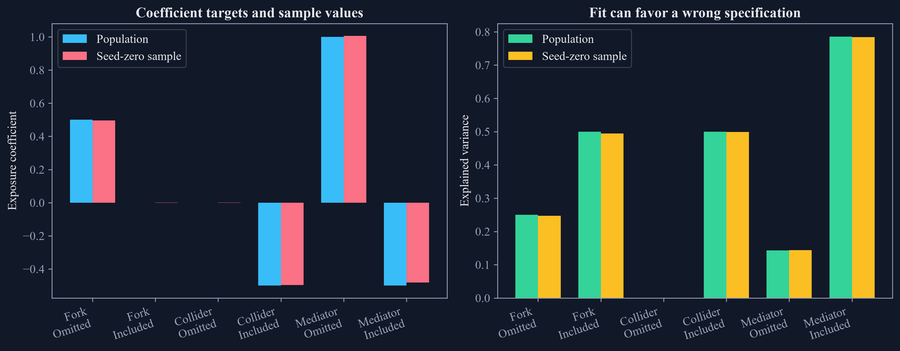

In [2]:
gap_rows = []
for structure in population_functions:
    population = population_functions[structure]()
    experiment = experiment_functions[structure]()
    for specification, population_diagnostics, sample_diagnostics in [("Conditioning variable omitted", population.unconditioned, experiment.unconditioned), ("Conditioning variable included", population.conditioned, experiment.conditioned)]:
        gap_rows.append({"Structure": structure, "Specification": specification, "Population exposure coefficient": coefficient_value(population_diagnostics, "X"), "Sample exposure coefficient": coefficient_value(sample_diagnostics, "X"), "Coefficient error": coefficient_value(sample_diagnostics, "X") - coefficient_value(population_diagnostics, "X"), "Population explained variance": population_diagnostics.r_squared, "Sample explained variance": sample_diagnostics.r_squared, "Explained-variance error": sample_diagnostics.r_squared - population_diagnostics.r_squared})
gap_table = pd.DataFrame(gap_rows)
save_table(gap_table, "specification_population_sample_gaps", "Population targets and seed-zero sample errors.", "tab:chapter26-specification-population-sample-gaps")
display(gap_table)

short_structure = {"Fork": "Fork", "Collider": "Collider", "Confounded mediator": "Mediator"}
labels = [f"{short_structure[row['Structure']]}\n{row['Specification'].replace('Conditioning variable ', '').title()}" for _, row in gap_table.iterrows()]
positions = np.arange(len(gap_table))
figure, axes = plt.subplots(1, 2, figsize=(12.1, 4.8))
axes[0].bar(positions - 0.18, gap_table["Population exposure coefficient"], width=0.36, color=palette["cyan"], label="Population")
axes[0].bar(positions + 0.18, gap_table["Sample exposure coefficient"], width=0.36, color=palette["rose"], label="Seed-zero sample")
axes[0].set_xticks(positions, labels, rotation=18, ha="right")
axes[0].set_ylabel("Exposure coefficient")
axes[0].set_title("Coefficient targets and sample values")
axes[0].legend()
axes[1].bar(positions - 0.18, gap_table["Population explained variance"], width=0.36, color=palette["green"], label="Population")
axes[1].bar(positions + 0.18, gap_table["Sample explained variance"], width=0.36, color=palette["amber"], label="Seed-zero sample")
axes[1].set_xticks(positions, labels, rotation=18, ha="right")
axes[1].set_ylabel("Explained variance")
axes[1].set_title("Fit can favor a wrong specification")
axes[1].legend()
figure.tight_layout()
save_figure(figure, "specification_population_sample_comparison")

## Checking convergence across repeated samples

Across $M$ generated samples, coefficient bias and root mean squared error are measured by:

$$
\widehat B_M
=\frac{1}{M}\sum_{m=1}^{M}(\widehat b_m-b^{\star}),
\qquad
\widehat{\operatorname{RMSE}}_M
=\sqrt{\frac{1}{M}\sum_{m=1}^{M}(\widehat b_m-b^{\star})^2}.
$$

Here, $M$ is the number of repeated generated samples, $\widehat b_m$ is the exposure coefficient in repetition $m$, $b^{\star}$ is its population target under the chosen specification, $\widehat B_M$ is estimated bias, and $\widehat{\operatorname{RMSE}}_M$ is estimated root mean squared error.

### Repeated-sample convergence to the population coefficient targets

In [3]:
sample_sizes = [50, 200, 1000, 5000]
repetitions = 30
convergence_rows = []
stored_estimates = {}
for structure in population_functions:
    population = population_functions[structure]()
    for specification, population_diagnostics in [("Omitted", population.unconditioned), ("Included", population.conditioned)]:
        target = coefficient_value(population_diagnostics, "X")
        for observations in sample_sizes:
            estimates = []
            explained_values = []
            for seed in range(repetitions):
                result = experiment_functions[structure](sample_size=observations, seed=seed)
                diagnostics = result.unconditioned if specification == "Omitted" else result.conditioned
                estimates.append(coefficient_value(diagnostics, "X"))
                explained_values.append(diagnostics.r_squared)
            estimates = np.asarray(estimates)
            stored_estimates[(structure, specification, observations)] = estimates
            convergence_rows.append({"Structure": structure, "Specification": specification, "Observations": observations, "Repetitions": repetitions, "Population coefficient": target, "Mean coefficient": estimates.mean(), "Bias": estimates.mean() - target, "Root mean squared error": np.sqrt(np.mean((estimates - target) ** 2)), "Coefficient standard deviation": estimates.std(ddof=1), "Mean explained variance": np.mean(explained_values)})
convergence_table = pd.DataFrame(convergence_rows)
save_table(convergence_table, "specification_repeated_convergence", "Repeated-sample convergence to the population coefficient targets.", "tab:chapter26-specification-convergence")
display(convergence_table);



,Structure,Specification,Observations,Repetitions,Population coefficient,Mean coefficient,Bias,Root mean squared error,Coefficient standard deviation,Mean explained variance
0,Fork,Omitted,50,30,0.5,0.518872,0.018872,0.102567,0.102539,0.281497
1,Fork,Omitted,200,30,0.5,0.517938,0.017938,0.0651,0.06365,0.259755
2,Fork,Omitted,1000,30,0.5,0.494737,-0.005263,0.039682,0.040003,0.248121
3,Fork,Omitted,5000,30,0.5,0.498641,-0.001359,0.015837,0.016048,0.24807
4,Fork,Included,50,30,0,0.005368,0.005368,0.128841,0.13093,0.540203
5,Fork,Included,200,30,0,0.009054,0.009054,0.07642,0.077179,0.51267
6,Fork,Included,1000,30,0,-0.005443,-0.005443,0.035506,0.035686,0.499761
7,Fork,Included,5000,30,0,-0.00361,-0.00361,0.011138,0.010717,0.499046
8,Collider,Omitted,50,30,0,0.026444,0.026444,0.151985,0.152226,0.023836
9,Collider,Omitted,200,30,0,-0.019779,-0.019779,0.062506,0.060308,0.004104


### Plotting the results

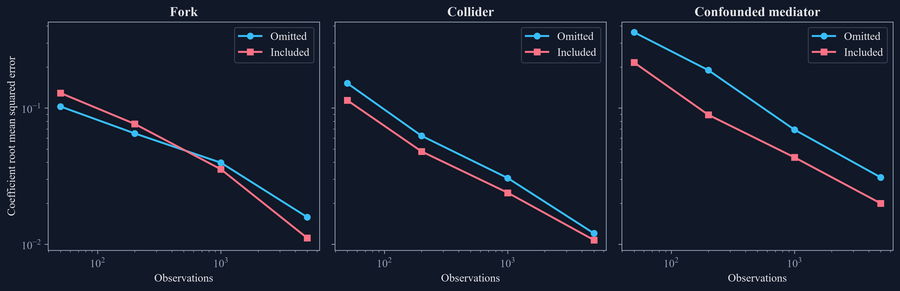

In [3]:
figure, axes = plt.subplots(1, 3, figsize=(13.0, 4.3), sharey=True)
for axis, structure in zip(axes, population_functions):
    subset = convergence_table[convergence_table["Structure"] == structure]
    for specification, color, marker in [("Omitted", palette["cyan"], "o"), ("Included", palette["rose"], "s")]:
        rows = subset[subset["Specification"] == specification]
        axis.plot(rows["Observations"], rows["Root mean squared error"], color=color, marker=marker, linewidth=2, label=specification)
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xlabel("Observations")
    axis.set_title(structure)
    axis.legend()
axes[0].set_ylabel("Coefficient root mean squared error")
figure.tight_layout()
save_figure(figure, "specification_convergence")

## Sampling variation does not settle the graph

Within a fixed declared model and specification, the sample coefficient approaches its population regression target:

$$
\widehat b_n\xrightarrow{p}b^{\star}
\qquad\text{as}\qquad n\to\infty.
$$

Here, $\widehat b_n$ is the sample exposure coefficient from $n$ observations, $b^{\star}$ is the population regression coefficient for that specification, and $\xrightarrow{p}$ denotes convergence in probability; the limit can still be noncausal when the specification conditions on the wrong variable or omits a required one.

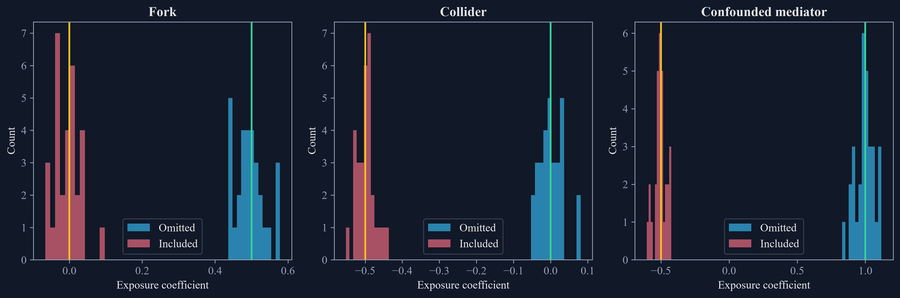

,Structure,Specification,Observations,Seeds,Population coefficient,Mean coefficient,Standard deviation,Smallest coefficient,Largest coefficient
0,Fork,Omitted,1000,30,0.5,0.494737,0.040003,0.435943,0.578
1,Fork,Included,1000,30,0,-0.005443,0.035686,-0.066357,0.097027
2,Collider,Omitted,1000,30,0,0.002738,0.031018,-0.053095,0.081056
3,Collider,Included,1000,30,-0.5,-0.497561,0.024178,-0.551832,-0.436417
4,Confounded mediator,Omitted,1000,30,1,0.995305,0.070285,0.82896,1.117738
5,Confounded mediator,Included,1000,30,-0.5,-0.503815,0.043984,-0.60474,-0.425111


In [4]:
seed_summary_rows = []
figure, axes = plt.subplots(1, 3, figsize=(13.0, 4.4))
for axis, structure in zip(axes, population_functions):
    omitted = stored_estimates[(structure, "Omitted", 1000)]
    included = stored_estimates[(structure, "Included", 1000)]
    population = population_functions[structure]()
    omitted_target = coefficient_value(population.unconditioned, "X")
    included_target = coefficient_value(population.conditioned, "X")
    seed_summary_rows.extend([
        {"Structure": structure, "Specification": "Omitted", "Observations": 1000, "Seeds": repetitions, "Population coefficient": omitted_target, "Mean coefficient": omitted.mean(), "Standard deviation": omitted.std(ddof=1), "Smallest coefficient": omitted.min(), "Largest coefficient": omitted.max()},
        {"Structure": structure, "Specification": "Included", "Observations": 1000, "Seeds": repetitions, "Population coefficient": included_target, "Mean coefficient": included.mean(), "Standard deviation": included.std(ddof=1), "Smallest coefficient": included.min(), "Largest coefficient": included.max()},
    ])
    axis.hist(omitted, bins=12, alpha=0.65, color=palette["cyan"], label="Omitted")
    axis.hist(included, bins=12, alpha=0.65, color=palette["rose"], label="Included")
    axis.axvline(omitted_target, color=palette["green"], linewidth=1.8)
    axis.axvline(included_target, color=palette["amber"], linewidth=1.8)
    axis.set_xlabel("Exposure coefficient")
    axis.set_ylabel("Count")
    axis.set_title(structure)
    axis.legend()
figure.tight_layout()
save_figure(figure, "specification_seed_distributions")
seed_summary_table = pd.DataFrame(seed_summary_rows)
save_table(seed_summary_table, "specification_seed_variation", "Coefficient variation across fixed-seed generated samples.", "tab:chapter26-specification-seed-variation")
display(seed_summary_table)

## Preserving a repeatable calculation record

### Invalid sample-size and seed checks for all three experiments

In [5]:
invalid_cases = [(3, 0), (True, 0), (4.5, 0), (1000001, 0), (10, True), (10, -1), (10, 2 ** 32)]
validity_rows = []
for structure, function in experiment_functions.items():
    for observations, seed in invalid_cases:
        result = contract_result(f"{structure}: sample={observations}, seed={seed}", lambda function=function, observations=observations, seed=seed: function(sample_size=observations, seed=seed), "ValueError")
        result["Structure"] = structure
        validity_rows.append(result)
validity_table = pd.DataFrame(validity_rows)[["Structure", "Check", "Expected result", "Observed result", "Passed"]]
save_table(validity_table, "specification_input_checks", "Invalid sample-size and seed checks for all three experiments.", "tab:chapter26-specification-input-checks")
display(validity_table)

first = fork_specification_experiment(sample_size=200, seed=17)
second = fork_specification_experiment(sample_size=200, seed=17)
different = fork_specification_experiment(sample_size=200, seed=18)
immutable_population = fork_population_diagnostics()
immutable_sample = fork_specification_experiment(sample_size=20, seed=3)
record_rows = [
    {"Check": "Same seed and size give the same record", "Passed": first == second},
    {"Check": "A different seed changes the record", "Passed": first != different},
    {"Check": "Population result has no mutable attribute dictionary", "Passed": not hasattr(immutable_population, "__dict__")},
    {"Check": "Sample result has no mutable attribute dictionary", "Passed": not hasattr(immutable_sample, "__dict__")},
    contract_result("Frozen strategy-performance record", lambda: setattr(collider_forecast_return(1.0, 1.0, 2.0), "correct", 0.0), "FrozenInstanceError"),
    contract_result("Immutable population tuple record", lambda: setattr(immutable_population, "structure", "changed"), "AttributeError"),
    contract_result("Immutable sample tuple record", lambda: setattr(immutable_sample, "structure", "changed"), "AttributeError"),
]
record_table = pd.DataFrame(record_rows)
save_table(record_table, "specification_record_checks", "Repeatability and immutable-record checks.", "tab:chapter26-specification-record-checks")
display(record_table);



,Structure,Check,Expected result,Observed result,Passed
0,Fork,"Fork: sample=3, seed=0",ValueError,ValueError,True
1,Fork,"Fork: sample=True, seed=0",ValueError,ValueError,True
2,Fork,"Fork: sample=4.5, seed=0",ValueError,ValueError,True
3,Fork,"Fork: sample=1000001, seed=0",ValueError,ValueError,True
4,Fork,"Fork: sample=10, seed=True",ValueError,ValueError,True
5,Fork,"Fork: sample=10, seed=-1",ValueError,ValueError,True
6,Fork,"Fork: sample=10, seed=4294967296",ValueError,ValueError,True
7,Collider,"Collider: sample=3, seed=0",ValueError,ValueError,True
8,Collider,"Collider: sample=True, seed=0",ValueError,ValueError,True
9,Collider,"Collider: sample=4.5, seed=0",ValueError,ValueError,True


,Check,Passed,Expected result,Observed result
0,Same seed and size give the same record,True,NaN,NaN
1,A different seed changes the record,True,NaN,NaN
2,Population result has no mutable attribute dic...,True,NaN,NaN
3,Sample result has no mutable attribute dictionary,True,NaN,NaN
4,Frozen strategy-performance record,True,FrozenInstanceError,FrozenInstanceError
5,Immutable population tuple record,True,AttributeError,AttributeError
6,Immutable sample tuple record,True,AttributeError,AttributeError


### How the three wrong specifications change the exposure coefficient

In [5]:
public_records = [StrategyPerformance, ColliderCoefficients, ColliderDiagnostics, PopulationRegressionDiagnostics, RegressionDiagnostics, SpecificationExperimentResult, SpecificationPopulationResult]
public_functions = [confounder_undercontrolled_coefficient, generalized_confounder_undercontrolled_coefficient, confounder_factor_return, confounder_forecast_return, collider_overcontrolled_coefficients, generalized_collider_overcontrolled_coefficients, collider_factor_return, collider_forecast_return, collider_model_diagnostics, fork_population_diagnostics, collider_population_diagnostics, confounded_mediator_population_diagnostics, fork_specification_experiment, collider_specification_experiment, confounded_mediator_specification_experiment]
surface_table = pd.DataFrame([
    {"Public group": "Result records", "Count": len(public_records), "Names": ", ".join(value.__name__ for value in public_records)},
    {"Public group": "Functions", "Count": len(public_functions), "Names": ", ".join(value.__name__ for value in public_functions)},
    {"Public group": "Total Chapter 26 surface", "Count": len(public_records) + len(public_functions), "Names": "All listed records and functions"},
])
save_table(surface_table, "specification_public_surface", "Released public records and functions covered by Chapter 26.", "tab:chapter26-specification-public-surface")
display(surface_table)

section_summary = pd.DataFrame([
    {"Structure": "Fork", "Wrong choice": "Omit the common cause", "Population exposure coefficient after wrong choice": 0.5, "Causal interpretation": "Noncausal association"},
    {"Structure": "Collider", "Wrong choice": "Include the common outcome", "Population exposure coefficient after wrong choice": -0.5, "Causal interpretation": "Selection-induced association"},
    {"Structure": "Confounded mediator", "Wrong choice": "Include the confounded mediator", "Population exposure coefficient after wrong choice": -0.5, "Causal interpretation": "Blocked effect plus opened path"},
])
save_table(section_summary, "specification_section_summary", "How the three wrong specifications change the exposure coefficient.", "tab:chapter26-specification-section-summary")
display(section_summary)

,Public group,Count,Names
0,Result records,7,"StrategyPerformance, ColliderCoefficients, Col..."
1,Functions,15,"confounder_undercontrolled_coefficient, genera..."
2,Total Chapter 26 surface,22,All listed records and functions


,Structure,Wrong choice,Population exposure coefficient after wrong choice,Causal interpretation
0,Fork,Omit the common cause,0.5,Noncausal association
1,Collider,Include the common outcome,-0.5,Selection-induced association
2,Confounded mediator,Include the confounded mediator,-0.5,Blocked effect plus opened path


## Tests

In [6]:
assert fork_population_diagnostics().unconditioned.coefficients == (0.0, 0.5)
assert fork_population_diagnostics().conditioned.coefficients == (0.0, 0.0, 1.0)
assert collider_population_diagnostics().conditioned.coefficients == (0.0, -0.5, 0.5)
assert confounded_mediator_population_diagnostics().unconditioned.r_squared == 1.0 / 7.0
assert confounded_mediator_population_diagnostics().conditioned.r_squared == 11.0 / 14.0
assert parity_table["Maximum difference"].max() < 1e-12
assert validity_table["Passed"].all()
assert record_table["Passed"].all()
assert surface_table.loc[surface_table["Public group"] == "Total Chapter 26 surface", "Count"].iloc[0] == 22
assert isinstance(fork_population_diagnostics(), SpecificationPopulationResult)
assert isinstance(fork_population_diagnostics().conditioned, PopulationRegressionDiagnostics)
assert isinstance(fork_specification_experiment(sample_size=20, seed=3), SpecificationExperimentResult)
assert isinstance(fork_specification_experiment(sample_size=20, seed=3).conditioned, RegressionDiagnostics)
for stem in ["specification_three_graphs", "specification_population_sample_comparison", "specification_convergence", "specification_seed_distributions"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["specification_population_targets", "specification_seed_zero_samples", "specification_visible_generation_parity", "specification_population_sample_gaps", "specification_repeated_convergence", "specification_seed_variation", "specification_input_checks", "specification_record_checks", "specification_public_surface", "specification_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()